# Лабораторная работа №4
## Метод k-ближайших соседей

**Выполнил:** Коршун Артём, группа P3319  
**Вариант:** 8, чётный номер в списке  
**Модуль:** 2. Методы машинного обучения

## Задание:

1. Выбрать датасет своего варианта: для чётного номера — вино, для нечётного — диабет.
2. Подготовить данные: проверить и обработать пропуски, при необходимости закодировать категориальные входы и выполнить масштабирование.
3. Получить и графически показать описательную статистику: количество значений, среднее, стандартное отклонение, минимум, максимум и квантили. Построить 3D-визуализацию признаков.
4. Самостоятельно реализовать метод k-ближайших соседей, используя из сторонних расчётных библиотек только NumPy и Pandas.
5. Построить два варианта модели: со случайно отобранными признаками и с фиксированным набором, выбранным заранее.
6. Проверить обе модели на тестовых данных при нескольких значениях k, включая 3, 5 и 10, и построить матрицы ошибок.

## Реализация:

### 1. Выбрать датасет своего варианта: для чётного номера — вино, для нечётного — диабет.

Мой номер в группе — 8, поэтому беру Wine. Одна строка — один образец вина. В таблице 13 измерений состава. По ним нужно определить, к какому из трёх классов относится вино. В столбце `class` числа 1, 2 и 3 обозначают эти классы.

В файле есть содержание алкоголя (`alcohol`), яблочная кислота (`malic_acid`), зольность и щёлочность золы (`ash`, `alcalinity_of_ash`), магний (`magnesium`), четыре показателя фенольных соединений, интенсивность и оттенок цвета (`color_intensity`, `hue`), оптическое измерение разбавленного вина (`od280_od315_of_diluted_wines`) и пролин (`proline`).


### 2. Подготовить данные: проверить и обработать пропуски, при необходимости закодировать категориальные входы и выполнить масштабирование.

Загружаю CSV, проверяю пропуски и типы столбцов. Из списка входов исключаю `class`, чтобы модель определяла класс по составу вина.

In [1]:
import numpy as np
import pandas as pd

SEED = 8
TARGET = "class"
df = pd.read_csv("data/wine.csv")
feature_columns = df.columns.drop(TARGET).tolist()
classes = np.sort(df[TARGET].unique())

assert df.shape == (178, 14)
assert set(classes) == {1, 2, 3}
assert len(feature_columns) == 13
assert df[feature_columns].select_dtypes(exclude="number").empty

quality = pd.DataFrame({
    "Показатель": ["Объекты", "Входные признаки", "Классы", "Пропущенные значения", "Полные дубликаты"],
    "Значение": [len(df), len(feature_columns), len(classes),
                 int(df.isna().sum().sum()), int(df.duplicated().sum())]
})
display(quality.set_index("Показатель"))
display(df.head())

class_distribution = df[TARGET].value_counts().sort_index().rename("Количество").to_frame()
class_distribution.index.name = "Класс"
class_distribution["Доля, %"] = 100 * class_distribution["Количество"] / len(df)
display(class_distribution.style.format({"Доля, %": "{:.2f}"}))

,Значение
Показатель,
Объекты,178
Входные признаки,13
Классы,3
Пропущенные значения,0
Полные дубликаты,0


,class,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315_of_diluted_wines,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


,Количество,"Доля, %"
Класс,,
1,59,33.15
2,71,39.89
3,48,26.97


В файле 178 образцов. К классу 1 относятся 59, к классу 2 — 71, к классу 3 — 48. Пропусков и полных дубликатов нет, все входы числовые. Здесь меняю только масштаб признаков.

Делю 178 вин примерно в пропорции 60/20/20.

- `train` — 106 вин. По ним считаю параметры обработки и среди них ищу ближайших соседей для новых вин.
- `validation` — 36 вин. На них сравниваю наборы признаков и значения `k`, чтобы выбрать настройку.
- `test` — ещё 36 вин. По ним проверяю качество после того, как настройка выбрана.

In [2]:
def stratified_holdout(indices, labels, fraction, seed):
    rng = np.random.default_rng(seed)
    kept, held = [], []
    for label in np.unique(labels[indices]):
        group = indices[labels[indices] == label].copy()
        rng.shuffle(group)
        n_held = int(round(len(group) * fraction))
        if not 0 < n_held < len(group):
            raise ValueError("Недостаточно объектов класса для разбиения")
        held.extend(group[:n_held])
        kept.extend(group[n_held:])
    return rng.permutation(kept), rng.permutation(held)

y_all = df[TARGET].to_numpy(dtype=int)
all_idx = np.arange(len(df))
pool_idx, test_idx = stratified_holdout(all_idx, y_all, 0.2, SEED)
train_idx, val_idx = stratified_holdout(pool_idx, y_all, 0.25, SEED + 1)
assert not set(train_idx) & set(val_idx)
assert not set(pool_idx) & set(test_idx)
assert set(train_idx) | set(val_idx) | set(test_idx) == set(all_idx)

split_rows = []
for name, idx in [("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
    row = {"Часть": name, "Объектов": len(idx), "Доля, %": 100 * len(idx) / len(df)}
    row.update({f"Класс {label}": int(np.sum(y_all[idx] == label)) for label in classes})
    split_rows.append(row)
split_table = pd.DataFrame(split_rows).set_index("Часть")
display(split_table.style.format({"Доля, %": "{:.2f}"}))

,Объектов,"Доля, %",Класс 1,Класс 2,Класс 3
Часть,,,,,
Train,106,59.55,35,43,28
Validation,36,20.22,12,14,10
Test,36,20.22,12,14,10


Среднее и стандартное отклонение каждого признака считаю по train. Затем применяю те же числа ко всем трём частям. Формула стандартизации — `(значение − среднее train) / std train`.

В ЛР 3 сопоставимый масштаб помогал градиентному спуску подбирать коэффициенты. В ЛР 4 он нужен для поиска соседей: без стандартизации разница в пролине, где значения измеряются сотнями, могла бы перекрыть разницу в алкоголе просто из-за масштаба чисел.

In [3]:
def fit_preprocessor(frame):
    medians = frame.median()
    if medians.isna().any():
        raise ValueError("Полностью пустой признак в обучении")
    filled = frame.fillna(medians)
    return {"columns": frame.columns.tolist(), "medians": medians,
            "means": filled.mean(), "stds": filled.std(ddof=0).replace(0, 1.0)}

def transform(frame, state):
    ordered = frame.loc[:, state["columns"]]
    values = ((ordered.fillna(state["medians"]) - state["means"]) / state["stds"]).to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Некорректные значения после обработки")
    return values

In [4]:
df_before_processing = df.copy(deep=True)
train_before = df.iloc[train_idx][feature_columns].copy()
check_state = fit_preprocessor(train_before)
check_X = transform(train_before, check_state)
train_after = pd.DataFrame(check_X, index=train_before.index, columns=feature_columns)

scale_check = pd.DataFrame({
    "Среднее до": train_before.mean(),
    "Std до": train_before.std(ddof=0),
    "Среднее после": train_after.mean(),
    "Std после": train_after.std(ddof=0)
})
display(scale_check.round(6))

shown_features = ["alcohol", "color_intensity", "proline"]
examples_before_after = pd.concat({
    "До": train_before[shown_features].head(3),
    "После": train_after[shown_features].head(3)
}, axis=1)
display(examples_before_after.round(4))

assert check_X.shape == (106, 13)
assert np.isfinite(check_X).all()
assert np.allclose(check_X.mean(axis=0), 0, atol=1e-12)
assert np.allclose(check_X.std(axis=0), 1, atol=1e-12)
assert df.equals(df_before_processing)
assert np.array_equal(y_all, df[TARGET].to_numpy())
print("Проверено: масштаб входов изменён; исходная таблица и ответы сохранены.")

,Среднее до,Std до,Среднее после,Std после
alcohol,12.987453,0.780091,0.0,1.0
malic_acid,2.308396,1.048419,-0.0,1.0
ash,2.357358,0.298917,0.0,1.0
alcalinity_of_ash,19.722642,3.537622,-0.0,1.0
magnesium,100.141509,14.961863,-0.0,1.0
total_phenols,2.258962,0.642968,0.0,1.0
flavanoids,2.007264,1.001813,0.0,1.0
nonflavanoid_phenols,0.351792,0.125742,0.0,1.0
proanthocyanins,1.561226,0.594666,0.0,1.0
color_intensity,4.921132,2.170353,0.0,1.0


До                           После                        
    alcohol color_intensity proline alcohol color_intensity proline
121   11.56            6.00     465 -1.8299          0.4971 -0.9506
25    13.05            3.58     830  0.0802         -0.6179  0.2391
7     14.06            5.05    1295  1.3749          0.0594  1.7546

Проверено: масштаб входов изменён; исходная таблица и ответы сохранены.


После пересчёта среднее каждого признака в train близко к 0, а стандартное отклонение — к 1. Например, в строке 121 значение `alcohol` стало −1.8299, потому что исходные 11.56 ниже среднего train 12.987453. Это та же строка с пересчитанными входами.

### 3. Получить и графически показать описательную статистику: количество значений, среднее, стандартное отклонение, минимум, максимум и квантили. Построить 3D-визуализацию признаков.

Считаю статистику по исходным 178 образцам. `count` — количество известных значений, `mean` — среднее, `std` — стандартное отклонение. Кроме минимума и максимума показываю квантили 5%, 25%, 50%, 75% и 95%. Например, квантиль 25% — граница, ниже которой лежит примерно четверть значений.

In [5]:
summary = df[feature_columns].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
summary.index.name = "Признак"
display(summary.style.format("{:.3f}"))
assert summary["count"].eq(178).all()

,count,mean,std,min,5%,25%,50%,75%,95%,max
Признак,,,,,,,,,,
alcohol,178.000,13.001,0.812,11.030,11.659,12.362,13.050,13.678,14.222,14.830
malic_acid,178.000,2.336,1.117,0.740,1.061,1.603,1.865,3.083,4.456,5.800
ash,178.000,2.367,0.274,1.360,1.920,2.210,2.360,2.558,2.742,3.230
alcalinity_of_ash,178.000,19.495,3.340,10.600,14.770,17.200,19.500,21.500,25.000,30.000
magnesium,178.000,99.742,14.282,70.000,80.850,88.000,98.000,107.000,124.300,162.000
total_phenols,178.000,2.295,0.626,0.980,1.380,1.742,2.355,2.800,3.275,3.880
flavanoids,178.000,2.029,0.999,0.340,0.545,1.205,2.135,2.875,3.498,5.080
nonflavanoid_phenols,178.000,0.362,0.124,0.130,0.190,0.270,0.340,0.438,0.600,0.660
proanthocyanins,178.000,1.591,0.572,0.410,0.730,1.250,1.555,1.950,2.709,3.580


У всех 13 признаков `count = 178`. Значения `alcohol` лежат между 11.03 и 14.83, а `proline` — между 278 и 1680. Такие разные масштабы и учитываю при подготовке k-NN.

In [6]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "figure.facecolor": "white", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 115
})
COLORS = {"random": "#D18B32", "fixed": "#3165A6"}
CLASS_COLORS = ["#3165A6", "#D18B32", "#418A70"]

Столбики гистограммы показывают, сколько вин попало в каждый интервал. Пунктир отмечает среднее, полоса вокруг него — среднее ± одно стандартное отклонение. Риски снизу отмечают минимум, пять квантилей и максимум. В заголовке указан размер выборки, а на отдельной диаграмме — число вин по классам.

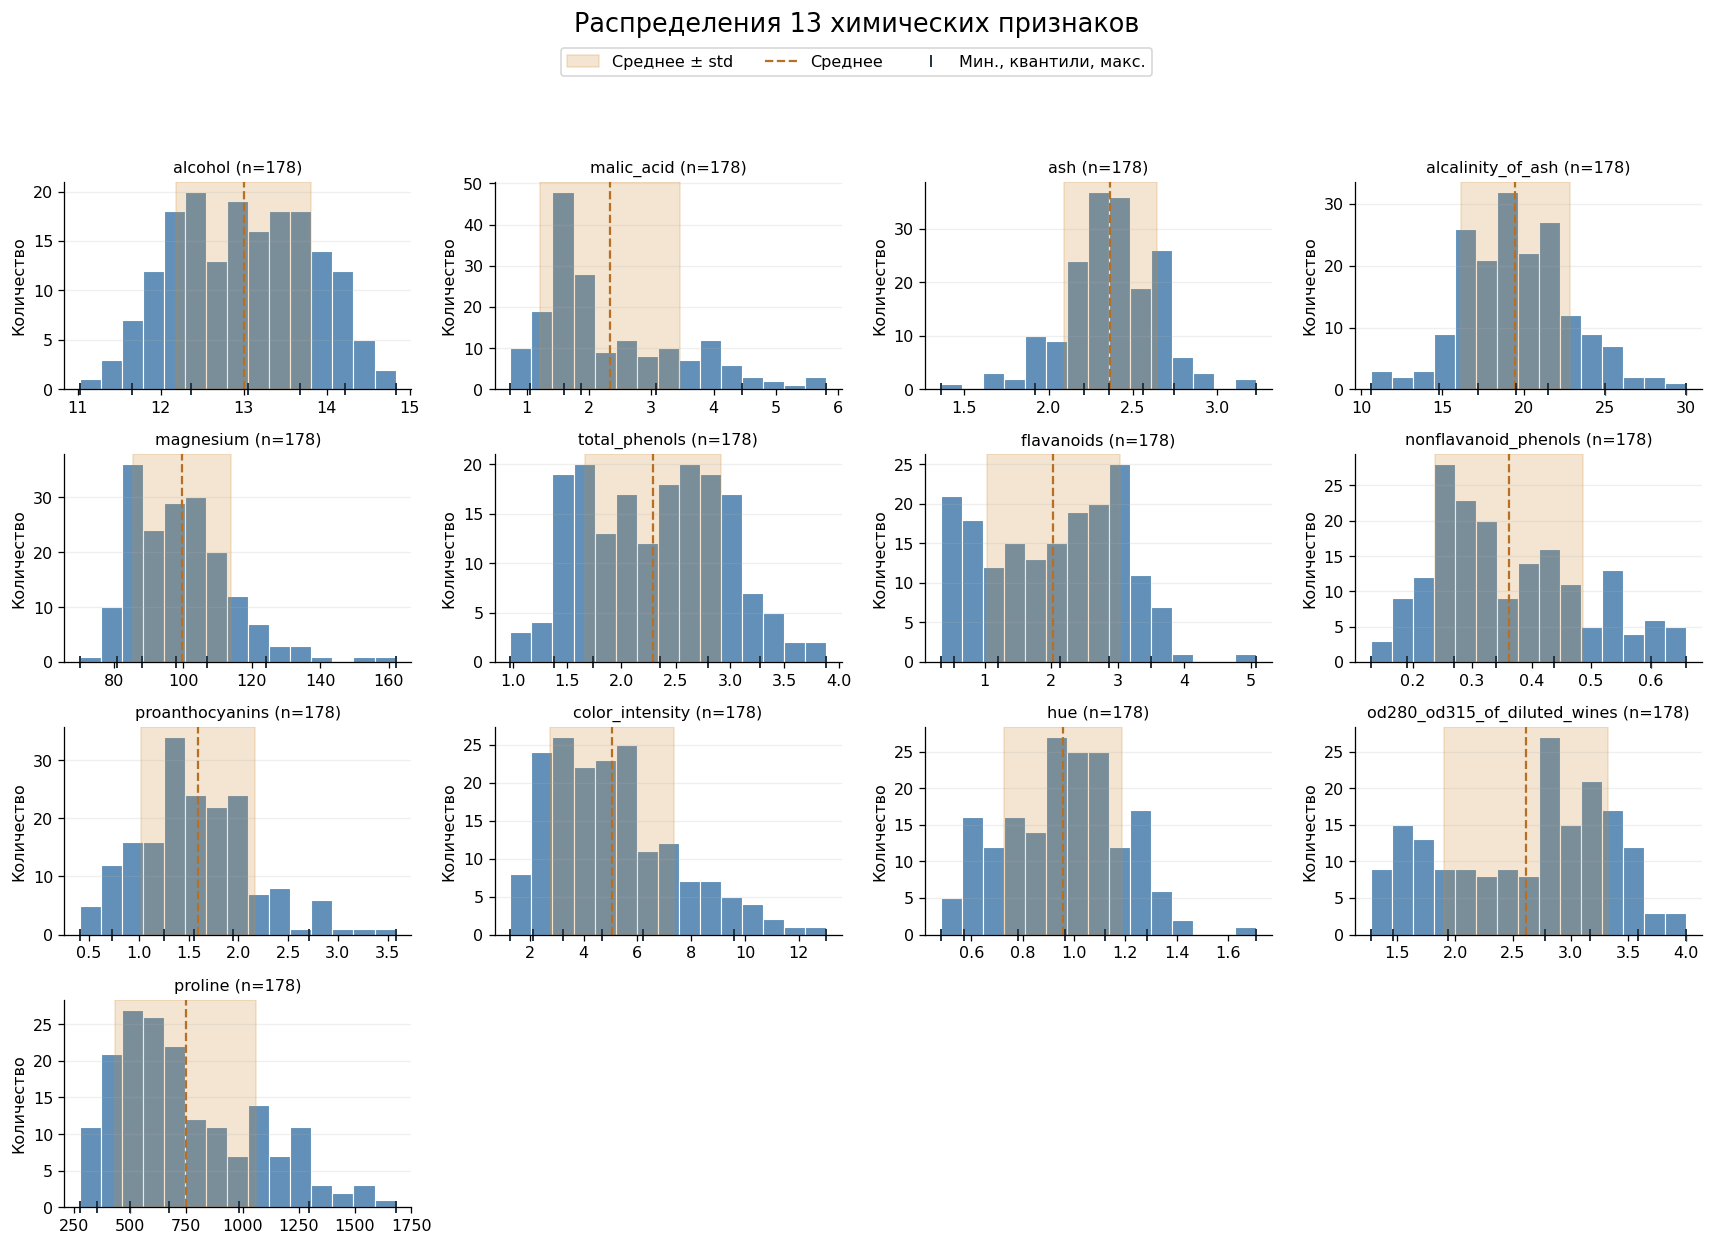

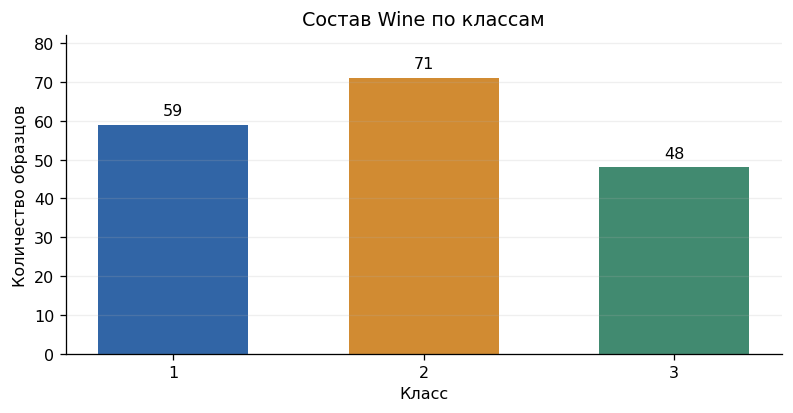

In [7]:
bounds = ["min", "5%", "25%", "50%", "75%", "95%", "max"]
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for feature, ax in zip(feature_columns, axes.flat):
    stats = summary.loc[feature]
    mean, std = stats["mean"], stats["std"]
    ax.hist(df[feature], bins=15, color="#6290B8", edgecolor="white", linewidth=0.7)
    ax.axvspan(mean - std, mean + std, color="#D18B32", alpha=0.22, label="Среднее ± std")
    ax.axvline(mean, color="#B66F23", linestyle="--", linewidth=1.4, label="Среднее")
    ax.plot(stats[bounds], [0] * len(bounds), "|", color="#273643", markersize=8,
            markeredgewidth=1.25, clip_on=False, label="Мин., квантили, макс.")
    ax.set_title(f"{feature} (n={int(stats['count'])})", fontsize=10)
    ax.set_ylabel("Количество")
    ax.grid(axis="y", alpha=0.2)
for ax in list(axes.flat)[len(feature_columns):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.957), ncol=3)
fig.suptitle("Распределения 13 химических признаков", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.7))
bars = ax.bar(class_distribution.index.astype(str), class_distribution["Количество"],
              color=CLASS_COLORS, width=0.6)
ax.bar_label(bars, padding=4)
ax.set(xlabel="Класс", ylabel="Количество образцов", title="Состав Wine по классам")
ax.set_ylim(0, 82)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

На 3D-графике одна точка — одно вино. По осям откладываю алкоголь, флавоноиды и интенсивность цвета. Цвет точки показывает исходный класс.

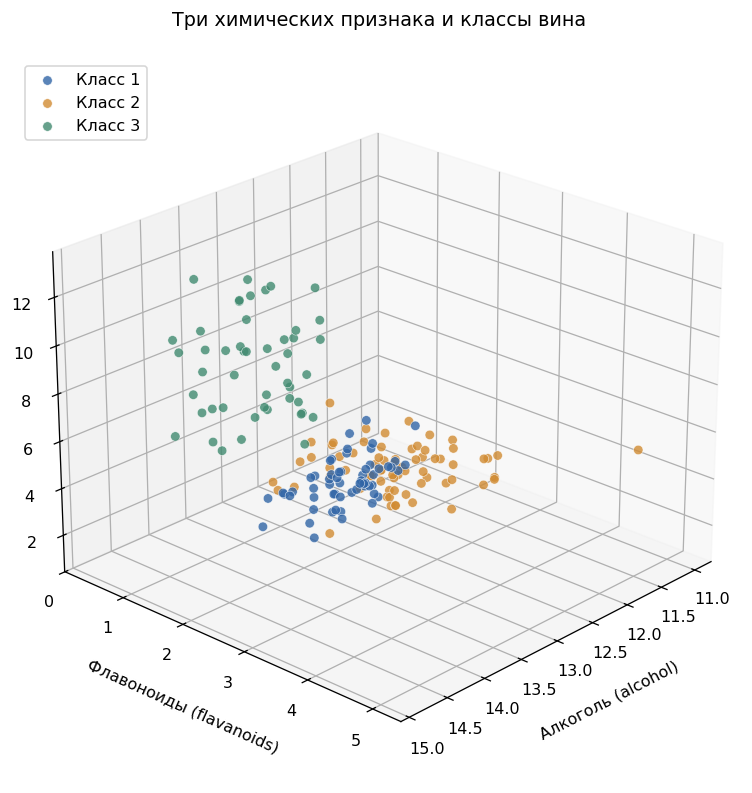

In [8]:
axes_features = ["alcohol", "flavanoids", "color_intensity"]
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
for label, color in zip(classes, CLASS_COLORS):
    part = df.loc[df[TARGET] == label]
    ax.scatter(part[axes_features[0]], part[axes_features[1]], part[axes_features[2]],
               color=color, s=35, alpha=0.8, edgecolor="white", linewidth=0.35,
               label=f"Класс {label}")
ax.set_xlabel("Алкоголь (alcohol)", labelpad=10)
ax.set_ylabel("Флавоноиды (flavanoids)", labelpad=10)
ax.set_zlabel("Интенсивность цвета", labelpad=9)
ax.set_title("Три химических признака и классы вина", pad=20)
ax.view_init(elev=24, azim=43)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

### 4. Самостоятельно реализовать метод k-ближайших соседей, используя из сторонних расчётных библиотек только NumPy и Pandas.

Для нового вина нахожу `k` ближайших образцов из обучения. Каждый голосует за свой класс, и побеждает класс с наибольшим числом голосов.

Близость считаю по одинаковым признакам. Если два значения отличаются на 2 и 1, квадрат расстояния равен `2² + 1² = 5`. Сравниваю квадраты расстояний. Взятие корня сохранило бы тот же порядок соседей. Значения беру после стандартизации, чтобы признаки с крупным числовым масштабом не определяли расстояние сами.

In [9]:
def knn_predict(X_train, y_train, X_query, k):
    if X_train.ndim != 2 or X_query.ndim != 2:
        raise ValueError("Признаки должны быть двумерными")
    if X_train.shape[1] != X_query.shape[1]:
        raise ValueError("Число признаков не совпадает")
    if len(X_train) != len(y_train) or not 1 <= k <= len(X_train):
        raise ValueError("Неверный размер обучения или k")
    predictions = []
    for query in X_query:
        distances_squared = np.sum((X_train - query) ** 2, axis=1)
        nearest = np.argsort(distances_squared, kind="stable")[:k]
        labels, votes = np.unique(y_train[nearest], return_counts=True)
        predictions.append(labels[np.argmax(votes)])
    return np.asarray(predictions, dtype=y_train.dtype)

def accuracy_manual(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if y_true.shape != y_pred.shape or y_true.ndim != 1 or len(y_true) == 0:
        raise ValueError("Нужны непустые одномерные ответы одинаковой формы")
    return float(np.sum(y_true == y_pred) / len(y_true))

def confusion_matrix_manual(y_true, y_pred, labels):
    label_to_index = {label: i for i, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)
    for actual, predicted in zip(y_true, y_pred):
        matrix[label_to_index[actual], label_to_index[predicted]] += 1
    return matrix

Проверяю на четырёх искусственных объектах. Для запроса `[2, 0]` при `k=3` ближайшие имеют классы 2, 1 и 2. По голосам ожидаю класс 2.

In [10]:
toy_X = np.array([[0., 0.], [0., 2.], [2., 0.], [2., 2.]])
toy_y = np.array([1, 1, 2, 2])
demo_query = np.array([2., 0.])
demo_k = 3

demo_distances = np.sum((toy_X - demo_query) ** 2, axis=1)
demo_order = np.argsort(demo_distances, kind="stable")
demo_neighbors = pd.DataFrame({
    "Номер известной строки": demo_order,
    "Координата 1": toy_X[demo_order, 0],
    "Координата 2": toy_X[demo_order, 1],
    "Класс": toy_y[demo_order],
    "Квадрат расстояния": demo_distances[demo_order],
    "В трёх ближайших": np.arange(len(demo_order)) < demo_k
})
display(demo_neighbors)

demo_labels, demo_votes = np.unique(toy_y[demo_order[:demo_k]], return_counts=True)
display(pd.DataFrame({"Класс": demo_labels, "Голоса": demo_votes}).set_index("Класс"))
demo_answer = knn_predict(toy_X, toy_y, np.array([demo_query]), demo_k)[0]
print("Ответ k-NN для запроса [2, 0] при k=3:", demo_answer)
assert demo_answer == 2

assert knn_predict(toy_X, toy_y, np.array([[2., 0.]]), 1)[0] == 2
assert knn_predict(toy_X, toy_y, np.array([[1., 1.]]), 4)[0] == 1
assert accuracy_manual([1, 2, 3], [1, 1, 3]) == 2 / 3
control_matrix = confusion_matrix_manual([1, 2, 3], [1, 1, 3], classes)
assert control_matrix.sum() == 3 and np.trace(control_matrix) == 2
print("Проверки ближайшего соседа, ничьей, accuracy и матрицы ошибок пройдены.")

,Номер известной строки,Координата 1,Координата 2,Класс,Квадрат расстояния,В трёх ближайших
0,2,2.0,0.0,2,0.0,True
1,0,0.0,0.0,1,4.0,True
2,3,2.0,2.0,2,4.0,True
3,1,0.0,2.0,1,8.0,False


,Голоса
Класс,
1,1
2,2


Ответ k-NN для запроса [2, 0] при k=3: 2
Проверки ближайшего соседа, ничьей, accuracy и матрицы ошибок пройдены.


Получился класс 2 с двумя голосами. В отдельной проверке при двух голосах за каждый класс функция выбрала класс 1, как задано правилом ничьей.

### 5. Построить два варианта модели: со случайно отобранными признаками и с фиксированным набором, выбранным заранее.

Один и тот же k-NN проверяю на двух наборах по четыре признака. Для `fixed` заранее выбираю алкоголь, флавоноиды, интенсивность цвета и пролин. Для `random` один раз случайно выбираю четыре разных входных столбца. Одинаковое число входов помогает сравнить именно состав наборов.

In [11]:
fixed_features = ["alcohol", "flavanoids", "color_intensity", "proline"]
rng_features = np.random.default_rng(SEED)
random_features = rng_features.choice(feature_columns, size=4, replace=False).tolist()
feature_sets = {"random": random_features, "fixed": fixed_features}
assert len(set(random_features)) == len(fixed_features) == 4
assert random_features != fixed_features
assert all(TARGET not in columns for columns in feature_sets.values())

feature_set_table = pd.DataFrame([
    {"Набор": name, "Количество": len(columns), "Признаки": ", ".join(columns)}
    for name, columns in feature_sets.items()
]).set_index("Набор")
display(feature_set_table)

,Количество,Признаки
Набор,,
random,4,"ash, alcalinity_of_ash, proline, nonflavanoid_..."
fixed,4,"alcohol, flavanoids, color_intensity, proline"


В `random` попали `ash`, `alcalinity_of_ash`, `proline` и `nonflavanoid_phenols`. Для каждого из двух наборов дальше использую те же строки и отдельно подбираю масштабы его четырёх столбцов.

### 6. Проверить обе модели на тестовых данных при нескольких значениях k, включая 3, 5 и 10, и построить матрицы ошибок.

Для двух наборов проверяю по три значения `k`, всего шесть сочетаний. 

Сначала сравниваю сочетания на validation. Если доли совпали, выбираю меньшее `k`, а при равенстве `k` — первое имя набора по алфавиту.

In [12]:
k_values = [3, 5, 10]
validation_rows = []
for model_name, columns in feature_sets.items():
    state = fit_preprocessor(df.iloc[train_idx][columns])
    X_train = transform(df.iloc[train_idx][columns], state)
    X_val = transform(df.iloc[val_idx][columns], state)
    for k in k_values:
        pred = knn_predict(X_train, y_all[train_idx], X_val, k)
        validation_rows.append({"model": model_name, "k": k,
                                "validation_accuracy": accuracy_manual(y_all[val_idx], pred),
                                "correct": int(np.sum(pred == y_all[val_idx]))})
validation_results = pd.DataFrame(validation_rows).sort_values(
    ["validation_accuracy", "k", "model"], ascending=[False, True, True]
).reset_index(drop=True)
chosen_model = validation_results.loc[0, "model"]
chosen_k = int(validation_results.loc[0, "k"])
assert len(validation_results) == 6

display(validation_results.style.format({"validation_accuracy": "{:.4f}"}))
print(f"Зафиксирован выбор по validation: набор {chosen_model}, k={chosen_k}.")

,model,k,validation_accuracy,correct
0,fixed,5,1.0000,36
1,fixed,10,1.0000,36
2,fixed,3,0.9722,35
3,random,10,0.8056,29
4,random,3,0.7500,27
5,random,5,0.7500,27


Зафиксирован выбор по validation: набор fixed, k=5.


У фиксированного набора `k=5` и `k=10` дали 36 верных ответов из 36 на validation. По правилу меньшего числа соседей выбираю `k=5`.

Затем объединяю train и validation. Получаю 142 известных образца, по ним заново считаю параметры обработки. На оставшихся 36 строках test показываю результаты всех шести сочетаний. Выбор модели уже сделан.

In [13]:
test_rows, matrices, test_predictions = [], {}, {}
for model_name, columns in feature_sets.items():
    state = fit_preprocessor(df.iloc[pool_idx][columns])
    X_pool = transform(df.iloc[pool_idx][columns], state)
    X_test = transform(df.iloc[test_idx][columns], state)
    for k in k_values:
        pred = knn_predict(X_pool, y_all[pool_idx], X_test, k)
        matrix = confusion_matrix_manual(y_all[test_idx], pred, classes)
        accuracy = accuracy_manual(y_all[test_idx], pred)
        assert matrix.sum() == len(test_idx)
        assert np.isclose(np.trace(matrix) / matrix.sum(), accuracy)
        matrices[(model_name, k)] = matrix
        test_predictions[(model_name, k)] = pred
        correct = int(np.sum(pred == y_all[test_idx]))
        test_rows.append({"model": model_name, "k": k, "test_accuracy": accuracy,
                          "correct": correct, "errors": len(test_idx) - correct,
                          "chosen_on_validation": model_name == chosen_model and k == chosen_k})
test_results = pd.DataFrame(test_rows)
comparison = test_results.merge(
    validation_results[["model", "k", "validation_accuracy"]], on=["model", "k"], validate="one_to_one"
)
comparison = comparison[["model", "k", "validation_accuracy", "test_accuracy", "correct", "errors", "chosen_on_validation"]]
assert len(comparison) == 6
assert comparison["chosen_on_validation"].sum() == 1

def emphasize_choice(row):
    return ["background-color: #E8F1E9; font-weight: bold" if row["chosen_on_validation"] else ""] * len(row)

display(comparison.style.format({"validation_accuracy": "{:.4f}", "test_accuracy": "{:.4f}"})
        .apply(emphasize_choice, axis=1))
majority_label = pd.Series(y_all[pool_idx]).value_counts().idxmax()
baseline_accuracy = accuracy_manual(y_all[test_idx], np.full(len(test_idx), majority_label))
print(f"Ориентир: всегда класс {majority_label}; test accuracy = {baseline_accuracy:.4f}.")

,model,k,validation_accuracy,test_accuracy,correct,errors,chosen_on_validation
0,random,3,0.7500,0.8056,29,7,False
1,random,5,0.7500,0.8333,30,6,False
2,random,10,0.8056,0.8056,29,7,False
3,fixed,3,0.9722,0.9722,35,1,False
4,fixed,5,1.0000,0.9722,35,1,True
5,fixed,10,1.0000,0.9722,35,1,False


Ориентир: всегда класс 2; test accuracy = 0.3889.


Случайный набор распознал 29, 30 и 29 вин из 36 при `k=3, 5, 10`. Фиксированный распознал 35 вин при каждом из трёх `k`. На этом разбиении состав признаков повлиял на результат сильнее, чем смена числа соседей.

На графике слева показана доля верных ответов на validation, справа — на test.

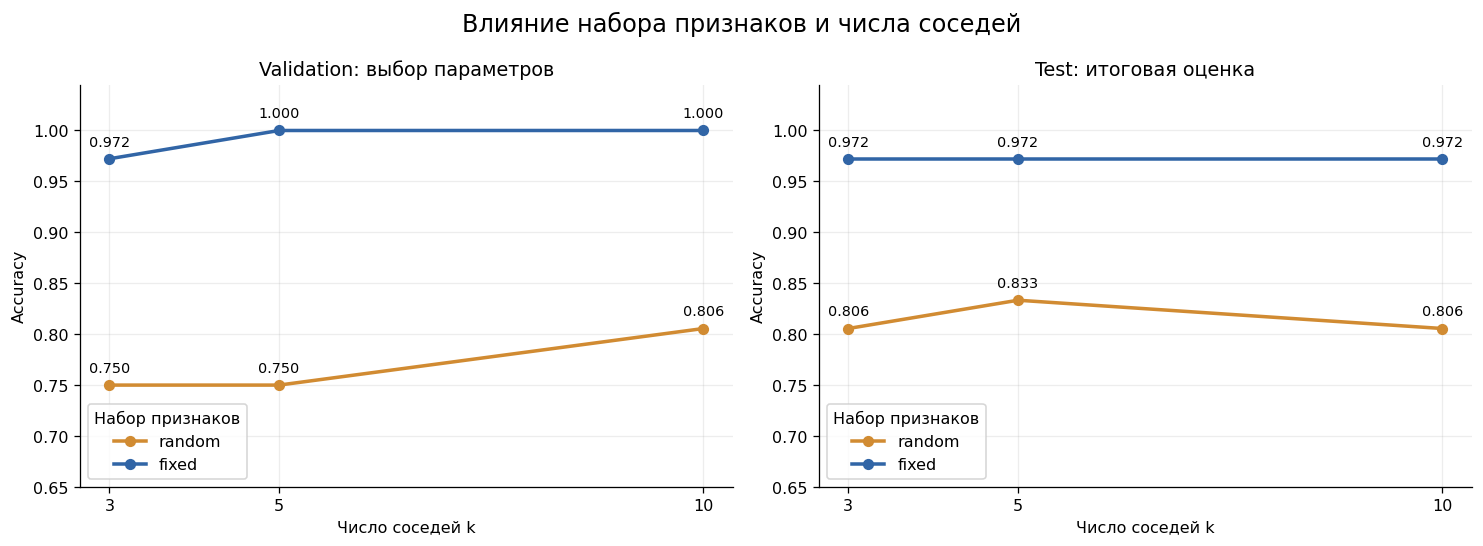

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for model_name in feature_sets:
    val_curve = validation_results.loc[validation_results["model"] == model_name].sort_values("k")
    test_curve = test_results.loc[test_results["model"] == model_name].sort_values("k")
    for ax, curve, metric in [(axes[0], val_curve, "validation_accuracy"),
                              (axes[1], test_curve, "test_accuracy")]:
        ax.plot(curve["k"], curve[metric], marker="o", linewidth=2.2,
                color=COLORS[model_name], label=model_name)
        for x, value in zip(curve["k"], curve[metric]):
            ax.annotate(f"{value:.3f}", (x, value), xytext=(0, 8),
                        textcoords="offset points", ha="center", fontsize=9)
for ax, title in zip(axes, ["Validation: выбор параметров", "Test: итоговая оценка"]):
    ax.set(title=title, xlabel="Число соседей k", ylabel="Accuracy", ylim=(0.65, 1.045))
    ax.set_xticks(k_values)
    ax.grid(alpha=0.22)
    ax.legend(title="Набор признаков")
fig.suptitle("Влияние набора признаков и числа соседей", fontsize=15)
fig.tight_layout()
plt.show()

В матрице ошибок строки — настоящие классы, столбцы — прогнозы. Число на диагонали показывает, сколько вин своего класса определили правильно. Сумма всех ячеек каждой матрицы равна 36.

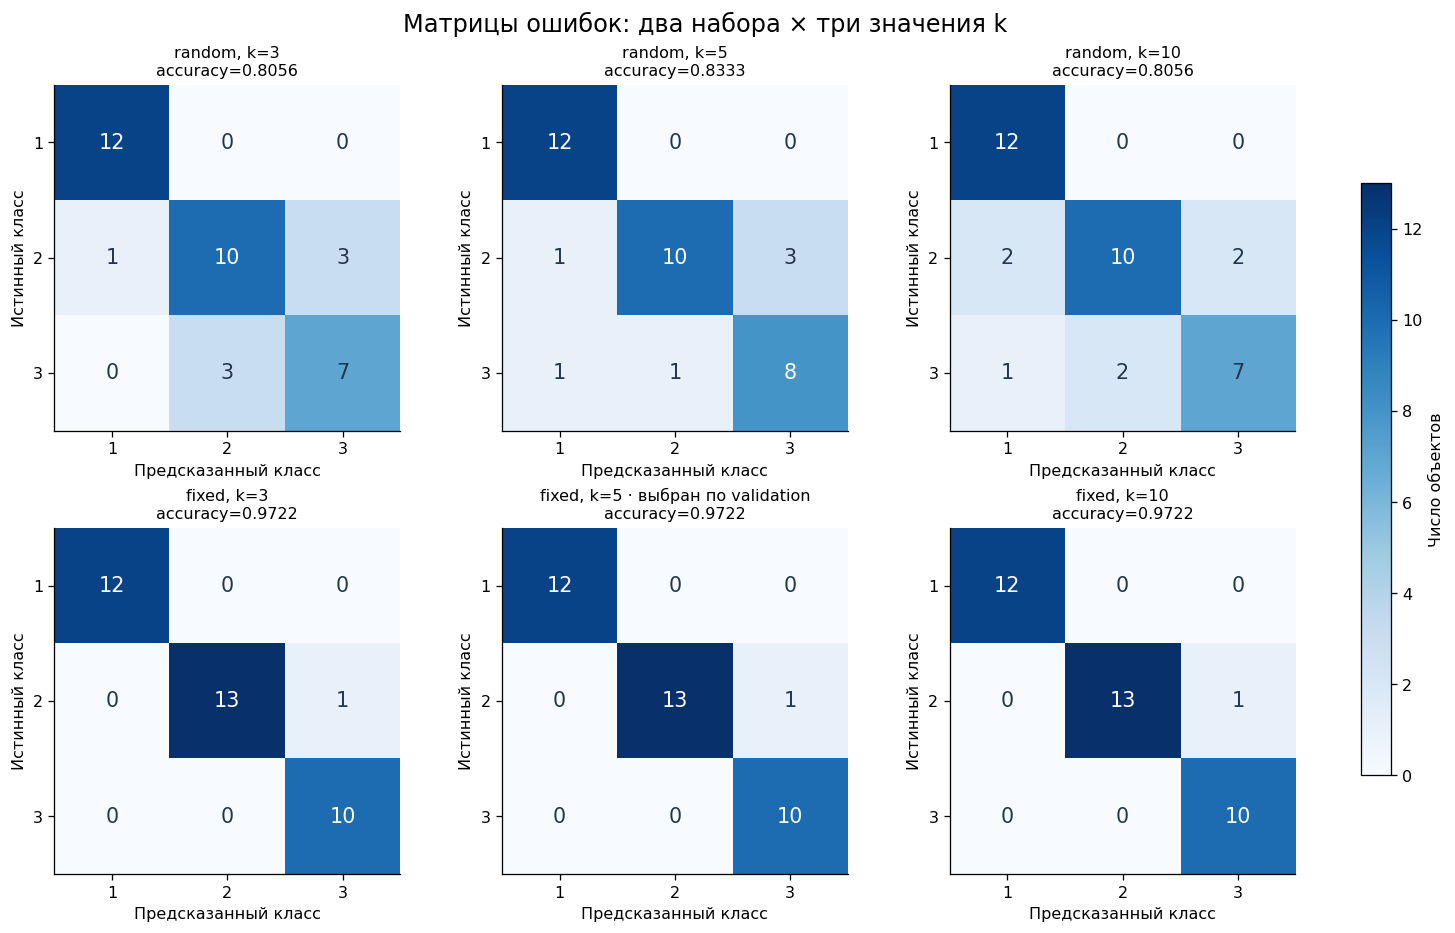

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
vmax = max(int(matrix.max()) for matrix in matrices.values())
for row, model_name in enumerate(feature_sets):
    for col, k in enumerate(k_values):
        ax = axes[row, col]
        matrix = matrices[(model_name, k)]
        image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
        for i in range(len(classes)):
            for j in range(len(classes)):
                color = "white" if matrix[i, j] > vmax * 0.55 else "#24364B"
                ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color=color, fontsize=13)
        accuracy = accuracy_manual(y_all[test_idx], test_predictions[(model_name, k)])
        ax.set_xticks(range(len(classes)), labels=classes)
        ax.set_yticks(range(len(classes)), labels=classes)
        ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс")
        selected = " · выбран по validation" if (model_name, k) == (chosen_model, chosen_k) else ""
        ax.set_title(f"{model_name}, k={k}{selected}\naccuracy={accuracy:.4f}", fontsize=10)
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75, label="Число объектов")
fig.suptitle("Матрицы ошибок: два набора × три значения k", fontsize=15)
plt.show()

Ниже отдельно показана матрица выбранного варианта и образец, на котором он ошибся.

In [16]:
chosen_prediction = test_predictions[(chosen_model, chosen_k)]
chosen_matrix = matrices[(chosen_model, chosen_k)]
chosen_accuracy = accuracy_manual(y_all[test_idx], chosen_prediction)
chosen_errors = int(np.sum(chosen_prediction != y_all[test_idx]))
chosen_matrix_frame = pd.DataFrame(chosen_matrix, index=classes, columns=classes)
chosen_matrix_frame.index.name = "Истинный класс"
chosen_matrix_frame.columns.name = "Предсказанный класс"
display(chosen_matrix_frame)

error_positions = test_idx[chosen_prediction != y_all[test_idx]]
error_examples = df.iloc[error_positions][fixed_features].copy()
error_examples.insert(0, "Истинный класс", y_all[error_positions])
error_examples.insert(1, "Прогноз", chosen_prediction[chosen_prediction != y_all[test_idx]])
display(error_examples)

final_summary = pd.DataFrame({
    "Показатель": ["Выбранный набор", "k", "Обучающий пул", "Test", "Верные ответы", "Ошибки", "Test accuracy", "Ориентир (постоянный класс)"],
    "Результат": [chosen_model, chosen_k, len(pool_idx), len(test_idx),
                  len(test_idx) - chosen_errors, chosen_errors, f"{chosen_accuracy:.4f}", f"{baseline_accuracy:.4f}"]
}).set_index("Показатель")
display(final_summary)

Предсказанный класс,1,2,3
Истинный класс,,,
1,12,0,0
2,0,13,1
3,0,0,10


,Истинный класс,Прогноз,alcohol,flavanoids,color_intensity,proline
61,2,3,12.64,1.41,5.75,450


,Результат
Показатель,
Выбранный набор,fixed
k,5
Обучающий пул,142
Test,36
Верные ответы,35
Ошибки,1
Test accuracy,0.9722
Ориентир (постоянный класс),0.3889


В строке класса 2 тринадцать вин распознаны правильно, а одно отнесено к классу 3. Это единственная ошибка выбранной модели. Всего на диагонали `12 + 13 + 10 = 35` верных ответов из 36, то есть 97.22%. Прогноз одним самым частым классом дал бы 14 из 36. Здесь один ответ меняет accuracy почти на 2.8 процентного пункта, поэтому результат относится к этой небольшой выборке.